# **1.Artificial Neural Network with Backpropagation**

## **Neural Network Class**

### Below is `SimpleNeuralNetwork` class (more about it is explained in the class and also in the document)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


class SimpleNeuralNetwork:
    """
    3-Layer Artificial Neural Network

    Input Layer   Hidden Layer  Output Layer

    Configurable:
    - Number of input nodes
    - Number of hidden nodes
    - Task: regression / classification
    - Activation function
    - Optimizer: batch / sgd / mini-batch
    - Weight initialization: random / xavier / he
    - L2 Regularization
    - Learning rate decay
    - Early stopping
    """

    # 1.Constructor
    def __init__(
        self,
        n_input,
        n_hidden,
        task,
        activation,
        optimizer,
        n_classes=None,
        learning_rate=0.01,
        epochs=1000,
        batch_size=None,
        weight_init='random',
        l2_lambda=0.0,
        lr_decay=0.0,
        early_stopping=False,
        patience=10
    ):

        self.n_input = n_input
        self.n_hidden = n_hidden
        self.task = task.lower()

        if self.task not in ['classification', 'regression']:
            raise ValueError("Task must be 'classification' or 'regression'")

        if self.task == 'regression':
            self.n_output = 1
        else:
            if n_classes is None:
                raise ValueError("n_classes must be provided for classification")
            self.n_output = n_classes

        self.activation_name = activation.lower()
        if self.activation_name not in ['sigmoid', 'tanh', 'relu']:
            raise ValueError("Activation must be 'sigmoid', 'tanh', or 'relu'")

        self.optimizer = optimizer.lower()
        if self.optimizer not in ['batch', 'sgd', 'mini-batch']:
            raise ValueError("Optimizer must be 'batch', 'sgd', or 'mini-batch'")

        if self.optimizer == 'mini-batch' and batch_size is None:
            raise ValueError("batch_size must be provided for mini-batch optimizer")

        self.learning_rate = learning_rate
        self.initial_lr = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.weight_init = weight_init.lower()

        self.l2_lambda = l2_lambda
        self.lr_decay = lr_decay
        self.early_stopping = early_stopping
        self.patience = patience

        self.best_loss = np.inf
        self.wait = 0

        self.train_loss_history = []
        self.val_loss_history = []
        self.train_acc_history = []
        self.val_acc_history = []

        # NEW: Test tracking
        self.test_loss_history = []
        self.test_acc_history = []

        self._initialize_weights()


    # 2.Weight Initialization
    def _initialize_weights(self):

        if self.weight_init == 'random':
            self.W1 = np.random.randn(self.n_input, self.n_hidden) * 0.01
            self.W2 = np.random.randn(self.n_hidden, self.n_output) * 0.01

        elif self.weight_init == 'xavier':
            self.W1 = np.random.randn(self.n_input, self.n_hidden) * np.sqrt(1 / self.n_input)
            self.W2 = np.random.randn(self.n_hidden, self.n_output) * np.sqrt(1 / self.n_hidden)

        elif self.weight_init == 'he':
            self.W1 = np.random.randn(self.n_input, self.n_hidden) * np.sqrt(2 / self.n_input)
            self.W2 = np.random.randn(self.n_hidden, self.n_output) * np.sqrt(2 / self.n_hidden)

        else:
            raise ValueError("Weight initialization must be 'random', 'xavier', or 'he'")

        self.b1 = np.zeros((1, self.n_hidden))
        self.b2 = np.zeros((1, self.n_output))


    # 3.Hidden Layer Activation Functions
    def _activation(self, z):

        if self.activation_name == 'sigmoid':
            return 1 / (1 + np.exp(-z))

        elif self.activation_name == 'tanh':
            return np.tanh(z)

        elif self.activation_name == 'relu':
            return np.maximum(0, z)

        else:
            raise ValueError("Unsupported activation")


    def _activation_derivative(self, z):

        if self.activation_name == 'sigmoid':
            a = 1 / (1 + np.exp(-z))
            return a * (1 - a)

        elif self.activation_name == 'tanh':
            return 1 - np.tanh(z) ** 2

        elif self.activation_name == 'relu':
            return np.where(z > 0, 1, 0)

        else:
            raise ValueError("Unsupported activation")


    # 4.Output Layer Activation
    def _output_activation(self, z):

        if self.task == 'regression':
            return z
        else:
            z = z - np.max(z, axis=1, keepdims=True)
            exp = np.exp(z)
            return exp / np.sum(exp, axis=1, keepdims=True)


    # 5.Loss Functions
    def _loss(self, y_true, y_pred):

        m = y_true.shape[0]

        if self.task == 'regression':
            loss = np.mean((y_true - y_pred) ** 2)
        else:
            if y_true.ndim == 1:
                y_true = np.eye(self.n_output)[y_true]
            epsilon = 1e-15
            y_pred = np.clip(y_pred, epsilon, 1 - epsilon)
            loss = -np.sum(y_true * np.log(y_pred)) / m

        l2_term = (self.l2_lambda / (2 * m)) * (
            np.sum(self.W1 ** 2) + np.sum(self.W2 ** 2)
        )

        return loss + l2_term


    def _loss_derivative(self, y_true, y_pred):

        m = y_true.shape[0]

        if self.task == 'regression':
            return (2 / m) * (y_pred - y_true)
        else:
            if y_true.ndim == 1:
                y_true = np.eye(self.n_output)[y_true]
            return (y_pred - y_true) / m


    # 6.Forward Propagation
    def forward(self, X):

        self.Z1 = X @ self.W1 + self.b1
        self.A1 = self._activation(self.Z1)

        self.Z2 = self.A1 @ self.W2 + self.b2
        self.A2 = self._output_activation(self.Z2)

        return self.A2


    # 7.Backward Propagation
    def backward(self, X, y):

        m = X.shape[0]

        dZ2 = self._loss_derivative(y, self.A2)

        self.dW2 = self.A1.T @ dZ2 + (self.l2_lambda / m) * self.W2
        self.db2 = np.sum(dZ2, axis=0, keepdims=True)

        dA1 = dZ2 @ self.W2.T
        dZ1 = dA1 * self._activation_derivative(self.Z1)

        self.dW1 = X.T @ dZ1 + (self.l2_lambda / m) * self.W1
        self.db1 = np.sum(dZ1, axis=0, keepdims=True)


    # 8.Parameter Update (Gradient Descent)
    def _update(self):

        self.W1 -= self.learning_rate * self.dW1
        self.b1 -= self.learning_rate * self.db1

        self.W2 -= self.learning_rate * self.dW2
        self.b2 -= self.learning_rate * self.db2


    # 9.Training Loop
    def fit(self, X_train, y_train, X_val=None, y_val=None, X_test=None, y_test=None):

        m = X_train.shape[0]

        for epoch in range(self.epochs):

            if self.lr_decay > 0:
                self.learning_rate = self.initial_lr / (1 + self.lr_decay * epoch)

            if self.optimizer == 'batch':
                self.forward(X_train)
                self.backward(X_train, y_train)
                self._update()

            elif self.optimizer == 'sgd':
                indices = np.random.permutation(m)
                X_shuff = X_train[indices]
                y_shuff = y_train[indices]

                for i in range(m):
                    Xi = X_shuff[i:i+1]
                    yi = y_shuff[i:i+1]
                    self.forward(Xi)
                    self.backward(Xi, yi)
                    self._update()

            elif self.optimizer == 'mini-batch':
                indices = np.random.permutation(m)
                X_shuff = X_train[indices]
                y_shuff = y_train[indices]

                for start in range(0, m, self.batch_size):
                    end = start + self.batch_size
                    self.forward(X_shuff[start:end])
                    self.backward(X_shuff[start:end], y_shuff[start:end])
                    self._update()

            # Train metrics
            train_pred = self.forward(X_train)
            train_loss = self._loss(y_train, train_pred)
            self.train_loss_history.append(train_loss)

            if self.task == 'classification':
                train_acc = self._accuracy(y_train, train_pred)
                self.train_acc_history.append(train_acc)

            # Test metrics
            if X_test is not None:
                test_pred = self.forward(X_test)
                test_loss = self._loss(y_test, test_pred)
                self.test_loss_history.append(test_loss)

                if self.task == 'classification':
                    test_acc = self._accuracy(y_test, test_pred)
                    self.test_acc_history.append(test_acc)

        print("\nTraining Complete")
        print("Final Training Loss:", self.train_loss_history[-1])


    # 10.Prediction
    def predict(self, X):

        y_pred = self.forward(X)

        if self.task == 'regression':
            return y_pred
        else:
            return np.argmax(y_pred, axis=1)


    # 11.Accuracy 
    def _accuracy(self, y_true, y_pred):

        if y_true.ndim > 1:
            y_true = np.argmax(y_true, axis=1)

        return np.mean(
            y_true ==
            np.argmax(y_pred, axis=1)
        )


    # 12.Plot Loss
    def plot_loss(self):

        plt.plot(self.train_loss_history, label="Train Loss")

        if len(self.test_loss_history) > 0:
            plt.plot(self.test_loss_history, label="Test Loss")

        plt.title("Training vs Test Loss")
        plt.xlabel("Epochs")
        plt.ylabel("Loss")
        plt.legend()
        plt.grid(True)
        plt.show()


    # 13.Plot Accuracy 
    def plot_accuracy(self):

        if self.task != 'classification':
            return

        plt.plot(self.train_acc_history, label="Train Accuracy")

        if len(self.test_acc_history) > 0:
            plt.plot(self.test_acc_history, label="Test Accuracy")

        plt.title("Training vs Test Accuracy")
        plt.xlabel("Epochs")
        plt.ylabel("Accuracy")
        plt.legend()
        plt.grid(True)
        plt.show()

Below code cell includes


*   XOR dataset with Gaussian Noise generator
*   Cosine dataset Generator
*   train-test split and train-val-test split functions



In [ ]:
# 1.XOR Dataset Generator (With Gaussian Noise)
def generate_xor_dataset(n_samples, noise_std=0.1, random_seed=None):
    """
    Generate XOR dataset with Gaussian noise.

    Parameters:
    n_samples : total number of samples
    noise_std : standard deviation of Gaussian noise
    random_seed : for reproducibility

    Returns:
    X : (n_samples, 2)
    y : (n_samples,)
    """

    if random_seed is not None:
        np.random.seed(random_seed)

    # Base XOR points
    X_base = np.array([
        [0, 0],
        [0, 1],
        [1, 0],
        [1, 1]
    ])

    y_base = np.array([0, 1, 1, 0])

    # Randomly sample from base patterns
    indices = np.random.choice(4, n_samples)

    X = X_base[indices]
    y = y_base[indices]

    # Add Gaussian noise to inputs
    X = X + np.random.normal(0, noise_std, X.shape)

    return X, y

# 2.Cosine Dataset Generator
def generate_cosine_dataset(n_samples, noise_std=0.0, random_seed=None):
    """
    Generate Cosine dataset.

    Parameters:
    n_samples : total number of samples
    noise_std : optional Gaussian noise on output
    random_seed : for reproducibility

    Returns:
    X : (n_samples, 1)
    y : (n_samples, 1)
    """

    if random_seed is not None:
        np.random.seed(random_seed)

    X = np.linspace(0, 2 * np.pi, n_samples).reshape(-1, 1)
    y = np.cos(X)

    # Optional noise on output
    if noise_std > 0:
        y = y + np.random.normal(0, noise_std, y.shape)

    return X, y


# 3.TrainTest Split
def train_test_split(X, y, test_ratio=0.2, shuffle=True, random_seed=None):
    """
    Split dataset into train and test sets.

    Returns:
    X_train, X_test, y_train, y_test
    """

    if random_seed is not None:
        np.random.seed(random_seed)

    n_samples = len(X)
    indices = np.arange(n_samples)

    if shuffle:
        np.random.shuffle(indices)

    split_index = int(n_samples * (1 - test_ratio))

    train_indices = indices[:split_index]
    test_indices = indices[split_index:]

    return (
        X[train_indices],
        X[test_indices],
        y[train_indices],
        y[test_indices]
    )


# 4.TrainValidationTest Split
def train_val_test_split(
    X,
    y,
    val_ratio=0.1,
    test_ratio=0.2,
    shuffle=True,
    random_seed=None
):
    """
    Split dataset into train, validation and test sets.

    Returns:
    X_train, X_val, X_test,
    y_train, y_val, y_test
    """

    if random_seed is not None:
        np.random.seed(random_seed)

    n_samples = len(X)
    indices = np.arange(n_samples)

    if shuffle:
        np.random.shuffle(indices)

    test_size = int(n_samples * test_ratio)
    val_size = int(n_samples * val_ratio)

    test_indices = indices[:test_size]
    val_indices = indices[test_size:test_size + val_size]
    train_indices = indices[test_size + val_size:]

    return (
        X[train_indices],
        X[val_indices],
        X[test_indices],
        y[train_indices],
        y[val_indices],
        y[test_indices]
    )

## **Training on XOR data with Noise**

### **XOR data with Gaussina noise Classification using 3-Layer ANN**

Architecture:
- Input Layer: 2 nodes
- Hidden Layer: 4 nodes
- Output Layer: 2 classes (XOR)

Activation: tanh  
Loss: Cross-Entropy  
Optimizer: Batch Gradient Descent  

In [ ]:
# Generate XOR dataset
n_samples = 5000
X, y = generate_xor_dataset(n_samples, noise_std=0.1, random_seed=42)

# Train-Test Split (80-20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_ratio=0.2, random_seed=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4000
Testing samples: 1000


In [ ]:
model = SimpleNeuralNetwork(
    n_input=2,
    n_hidden=4,
    task='classification',
    activation='tanh',
    optimizer='batch',
    n_classes=2,
    learning_rate=0.05,
    epochs=2000,
    weight_init='xavier',
    l2_lambda=0.0,
    lr_decay=0.0
)

model.fit(X_train, y_train, X_test=X_test, y_test=y_test)


Training Complete
Final Training Loss: 0.025050852573437865


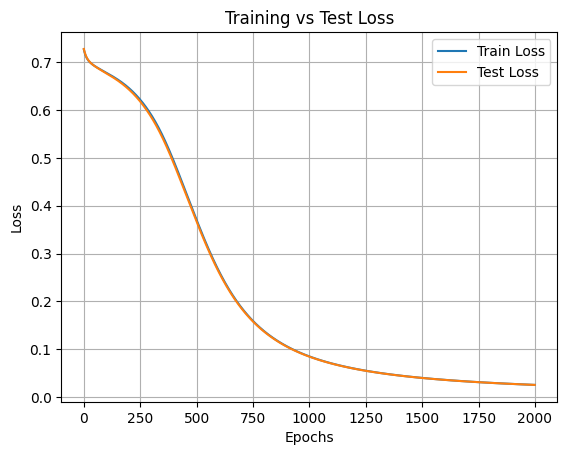

In [ ]:
model.plot_loss()

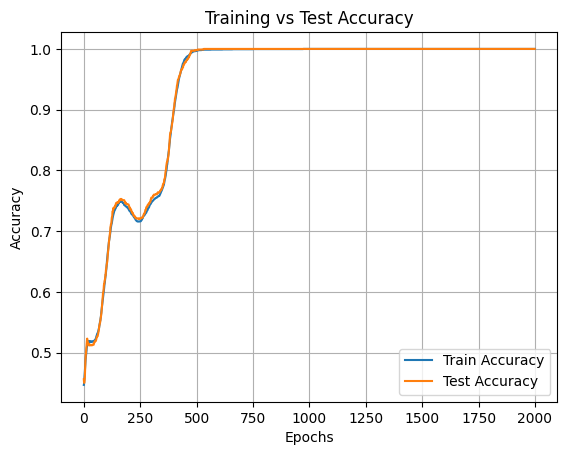

In [ ]:
model.plot_accuracy()

In [ ]:
train_pred = model.forward(X_train)
test_pred = model.forward(X_test)

train_loss = model._loss(y_train, train_pred)
test_loss = model._loss(y_test, test_pred)

train_acc = model._accuracy(y_train, train_pred)
test_acc = model._accuracy(y_test, test_pred)

print("Final Training Loss:", train_loss)
print("Final Testing Loss:", test_loss)
print("Final Training Accuracy:", train_acc)
print("Final Testing Accuracy:", test_acc)

Final Training Loss: 0.025050852573437865
Final Testing Loss: 0.025002363255916316
Final Training Accuracy: 1.0
Final Testing Accuracy: 1.0


#### Observations

- The training loss decreases steadily over epochs.
- The testing loss follows a similar trend, indicating good generalization.
- The network successfully learns the non-linear XOR boundary.
- Final training and testing accuracy are high, showing correct classification.
- The 2-hidden-neuron architecture is sufficient to solve XOR.

### **Deterministic Gradient Descent Experiment**

We analyze the effect of number of training samples (n)
on model performance.

Values tested:
- n = 100
- n = 500
- n = 2000


Training with n = 100

Training Complete
Final Training Loss: 0.057812012520204806
Train Accuracy: 1.0
Test Accuracy: 1.0


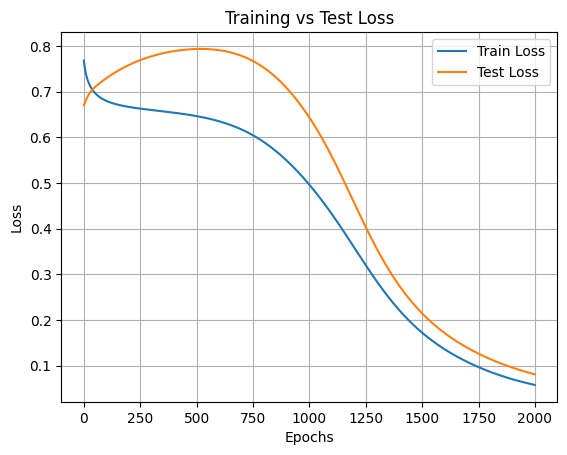

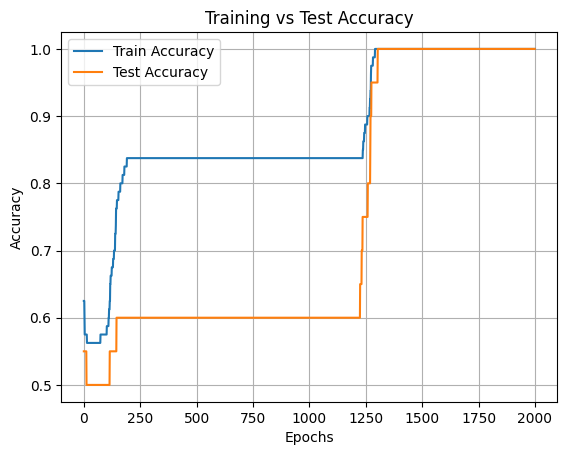


Training with n = 500

Training Complete
Final Training Loss: 0.05578802688987598
Train Accuracy: 1.0
Test Accuracy: 1.0


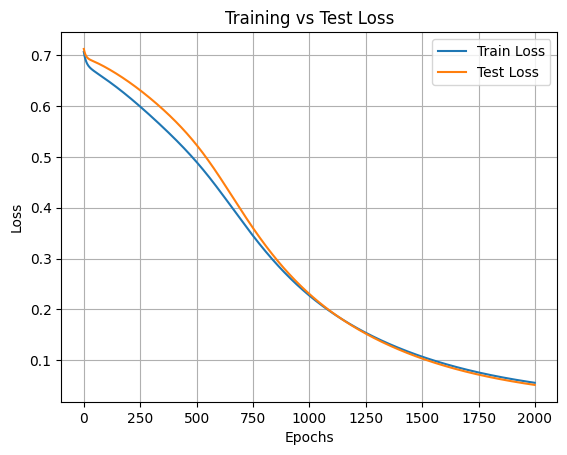

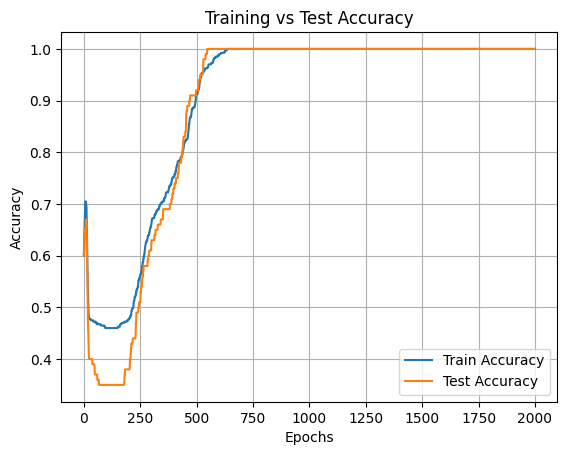


Training with n = 2000

Training Complete
Final Training Loss: 0.03722339189023011
Train Accuracy: 1.0
Test Accuracy: 1.0


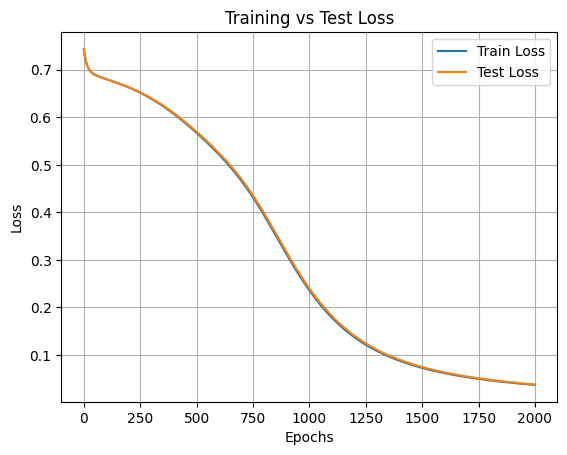

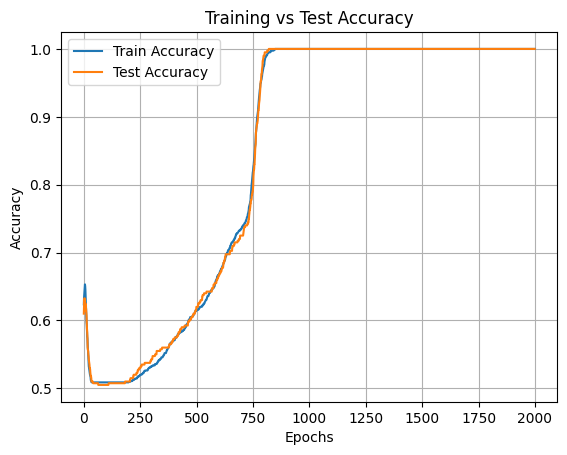

In [ ]:
sample_sizes = [100, 500, 2000]

results = {}

for n in sample_sizes:

    print(f"\nTraining with n = {n}")

    # Generate XOR dataset
    X, y = generate_xor_dataset(n, noise_std=0.1, random_seed=42)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_ratio=0.2, random_seed=42
    )

    model = SimpleNeuralNetwork(
        n_input=2,
        n_hidden=4,
        task='classification',
        activation='tanh',
        optimizer='batch',
        n_classes=2,
        learning_rate=0.05,
        epochs=2000,
        weight_init='xavier'
    )

    # Train the model
    model.fit(X_train, y_train, X_test=X_test, y_test=y_test)

    # Final predictions after training
    train_pred = model.forward(X_train)
    test_pred = model.forward(X_test)

    # Final accuracy
    train_acc = model._accuracy(y_train, train_pred)
    test_acc = model._accuracy(y_test, test_pred)

    results[n] = (train_acc, test_acc)


    # below it should be train and tet accuracy
    print("Train Accuracy:", train_acc)  
    print("Test Accuracy:", test_acc)


    model.plot_loss()
    model.plot_accuracy()

#### Observations on Sample Size (n)

- For small n (e.g., 100), the model shows higher variance.
- As n increases, training becomes more stable.
- Larger n improves generalization performance.
- Testing accuracy improves with larger datasets.
- Deterministic GD benefits from larger training data.

### **Gradient Descent Experiment (Effect of Batch Size m)**

In this experiment:
- Number of samples (n) is fixed.
- We vary batch size m.
- We observe its effect on:
  - Loss
  - Accuracy
  - Convergence behavior

Batch sizes tested:
- m = 1 (Pure SGD)
- m = 32 (Mini-batch)
- m = 128 (Larger Mini-batch)

In [ ]:
# Fixed dataset size
n_fixed = 1000

X, y = generate_xor_dataset(n_fixed, noise_std=0.1, random_seed=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_ratio=0.2, random_seed=42
)

In [ ]:
batch_sizes = [1, 32, 128]

sgd_results = {}

for m in batch_sizes:

    print(f"\nTraining with batch size m = {m}")

    if m == 1:
        optimizer_type = 'sgd'
        batch_size = None
    else:
        optimizer_type = 'mini-batch'
        batch_size = m

    # Initialize model with stable XOR parameters
    model = SimpleNeuralNetwork(
        n_input=2,
        n_hidden=4,
        task='classification',
        activation='tanh',
        optimizer=optimizer_type,
        n_classes=2,
        learning_rate=0.01,
        epochs=1000,
        batch_size=batch_size,
        weight_init='xavier'
    )

    # Train with test tracking
    model.fit(X_train, y_train, X_test=X_test, y_test=y_test)

    # Final predictions and metrics
    train_pred = model.forward(X_train)
    test_pred = model.forward(X_test)

    train_acc = model._accuracy(y_train, train_pred)
    test_acc = model._accuracy(y_test, test_pred)

    train_loss = model._loss(y_train, train_pred)
    test_loss = model._loss(y_test, test_pred)

    # Store results including model object for plotting
    sgd_results[m] = {
        "train_acc": train_acc,
        "test_acc": test_acc,
        "train_loss": train_loss,
        "test_loss": test_loss,
        "model": model       # store trained model for plotting
    }

    # below train and test accuracy will not make any sense
    print("Train Accuracy:", train_acc)
    print("Test Accuracy:", test_acc)
    print("Train Loss:", train_loss)
    print("Test Loss:", test_loss)


Training with batch size m = 1

Training Complete
Final Training Loss: 0.0001676519321506676
Train Accuracy: 1.0
Test Accuracy: 1.0
Train Loss: 0.0001676519321506676
Test Loss: 0.00029534368522428367

Training with batch size m = 32

Training Complete
Final Training Loss: 0.007769712608541126
Train Accuracy: 1.0
Test Accuracy: 1.0
Train Loss: 0.007769712608541126
Test Loss: 0.008748744083445942

Training with batch size m = 128

Training Complete
Final Training Loss: 0.048406429638040496
Train Accuracy: 1.0
Test Accuracy: 1.0
Train Loss: 0.048406429638040496
Test Loss: 0.04798643482212801


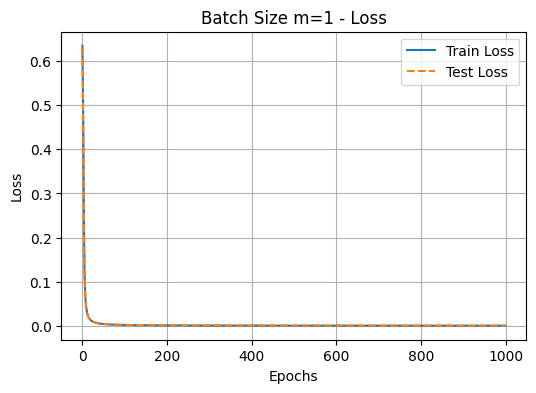

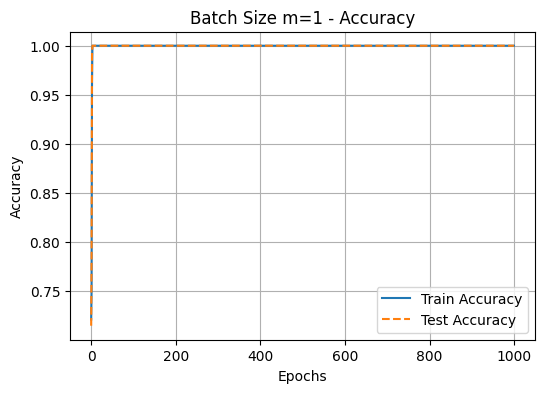

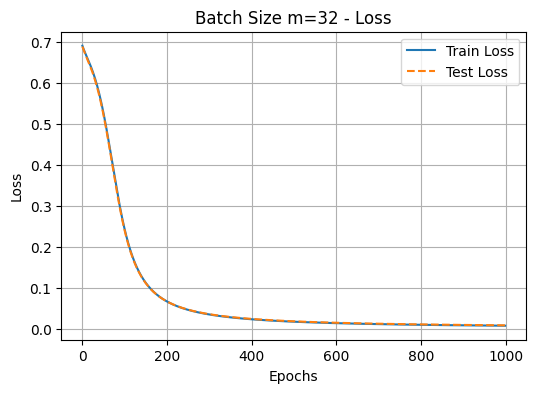

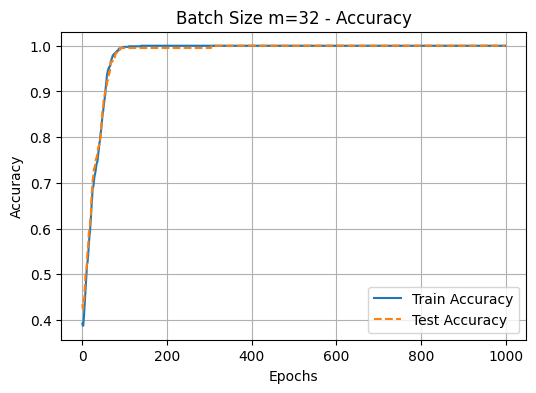

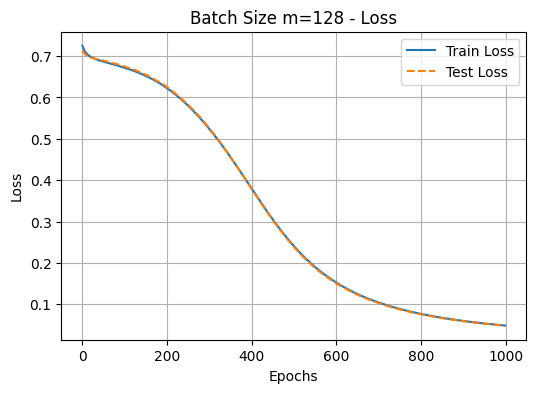

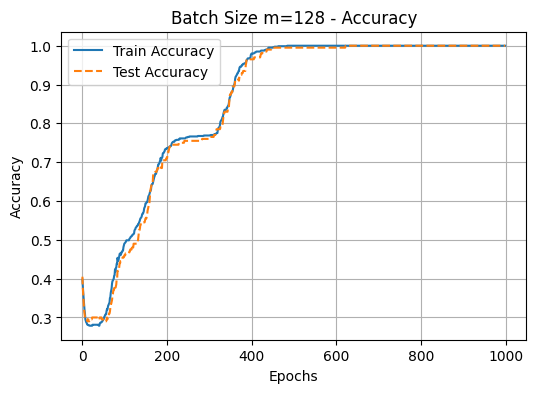

In [ ]:
for m in batch_sizes:
    model = sgd_results[m]["model"]  # Access stored model

    # Plot Loss
    plt.figure(figsize=(6,4))
    plt.plot(model.train_loss_history, label="Train Loss")
    plt.plot(model.test_loss_history, '--', label="Test Loss")
    plt.title(f"Batch Size m={m} - Loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

    # Plot Accuracy
    plt.figure(figsize=(6,4))
    plt.plot(model.train_acc_history, label="Train Accuracy")
    plt.plot(model.test_acc_history, '--', label="Test Accuracy")
    plt.title(f"Batch Size m={m} - Accuracy")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.show()

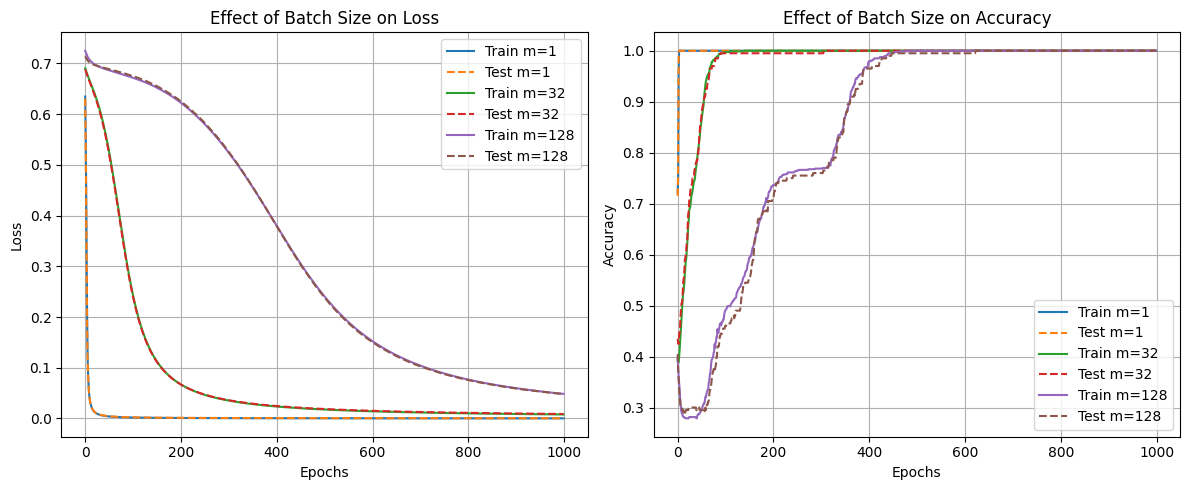

In [ ]:
plt.figure(figsize=(12,5))

# Combined Training & Test Loss
plt.subplot(1, 2, 1)
for m in batch_sizes:
    model = sgd_results[m]["model"]
    plt.plot(model.train_loss_history, label=f"Train m={m}")
    plt.plot(model.test_loss_history, '--', label=f"Test m={m}")
plt.title("Effect of Batch Size on Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

# Combined Training & Test Accuracy
plt.subplot(1, 2, 2)
for m in batch_sizes:
    model = sgd_results[m]["model"]
    plt.plot(model.train_acc_history, label=f"Train m={m}")
    plt.plot(model.test_acc_history, '--', label=f"Test m={m}")
plt.title("Effect of Batch Size on Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

#### Observations on Batch Size (m)

- m = 1 (Pure SGD):
  - generally Loss curve is noisy(but above we cannot observe due to a close optimal hyperparameters, same for below two points).
  - Faster updates but high variance.
  - Converges but fluctuates.

- m = 32:
  - More stable training.
  - Good balance between speed and stability.
  - Often best practical performance.

- m = 128:
  - Very smooth loss curve.
  - More stable but slower updates.
  - Similar performance to batch gradient descent.

Conclusion:
Smaller batch sizes introduce noise in gradient updates, which can help escape local minima.
Larger batch sizes provide stable convergence but may require more epochs.

## **Training on Cosine data with Noise**

### **Cosine data with Noise learning using 3-Layer ANN**

Architecture:
- Input Layer: 2 nodes
- Hidden Layer: 4 nodes
- Output Layer: 1 node

Activation: tanh  
Loss: MSME
Optimizer: Batch Gradient Descent  

In [ ]:
n_samples = 5000
X, y = generate_cosine_dataset(n_samples, noise_std=0.1, random_seed=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_ratio=0.2, random_seed=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4000
Testing samples: 1000


In [ ]:
model = SimpleNeuralNetwork(
    n_input=1,
    n_hidden=10,
    task='regression',
    activation='tanh',
    optimizer='batch',
    learning_rate=0.01,
    epochs=1000,
    weight_init='xavier',
    l2_lambda=0.001,
    lr_decay=0.0
)

model.fit(X_train, y_train, X_test=X_test, y_test=y_test)


Training Complete
Final Training Loss: 0.29540039410944735


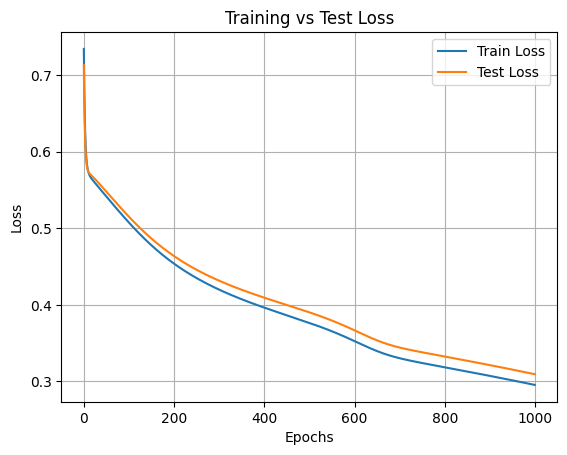

In [ ]:
model.plot_loss()

In [ ]:
print("Last epoch loss from history:", model.train_loss_history[-1])
print("Final Training Loss recalculated:", train_loss)

Last epoch loss from history: 0.29540039410944735
Final Training Loss recalculated: 0.012662135626971598


In [ ]:
train_pred = model.forward(X_train)
test_pred = model.forward(X_test)

train_loss = model._loss(y_train, train_pred)
test_loss = model._loss(y_test, test_pred)

print("Final Training Loss:", train_loss)
print("Final Testing Loss:", test_loss)

Final Training Loss: 0.29540039410944735
Final Testing Loss: 0.3093881215800889


#### Observations

- The training and testing loss curves should decrease smoothly, showing convergence.
- Since this is regression, accuracy is not applicable; the primary metric is mean squared error.
- Final losses give insight into how well the network approximates the cosine function.

### **Deterministic Gradient Descent Experiment**

We analyze the effect of number of training samples (n)
on model performance.

Values tested:
- n = 100
- n = 500
- n = 2000


Training with n = 100

Training Complete
Final Training Loss: 0.19142691158319128
Train Loss: 0.19142691158319128
Test Loss: 0.26247838568841825


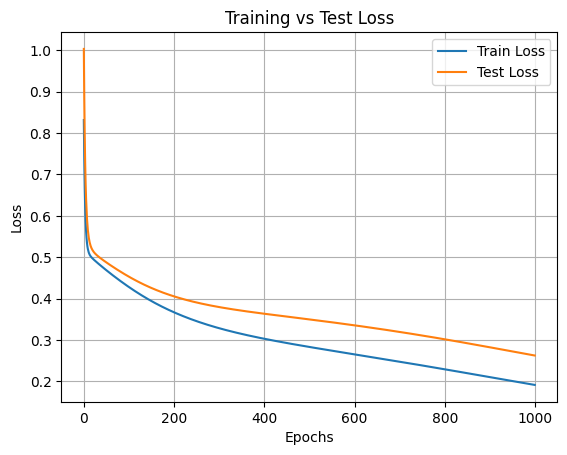


Training with n = 500

Training Complete
Final Training Loss: 0.21370015199714412
Train Loss: 0.21370015199714412
Test Loss: 0.23324142794216296


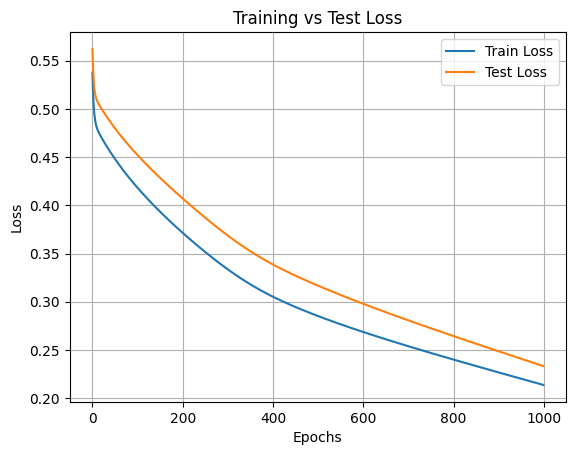


Training with n = 2000

Training Complete
Final Training Loss: 0.1886340666849125
Train Loss: 0.1886340666849125
Test Loss: 0.18884935943040207


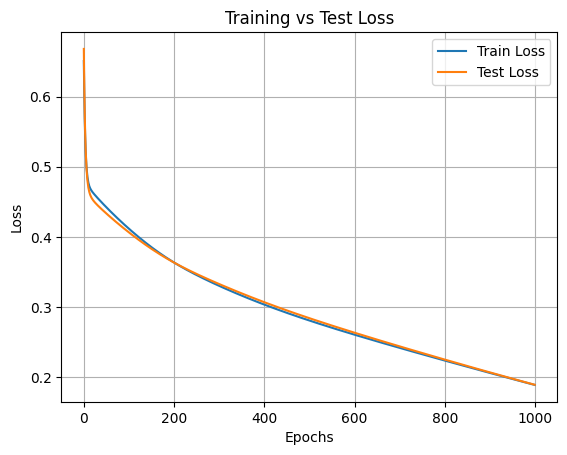

In [ ]:
sample_sizes = [100, 500, 2000]

results = {}

for n in sample_sizes:

    print(f"\nTraining with n = {n}")

    X, y = generate_cosine_dataset(n, noise_std=0.1, random_seed=42)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_ratio=0.2, random_seed=42
    )

    model = SimpleNeuralNetwork(
        n_input=1,
        n_hidden=10,
        task='regression',
        activation='tanh',
        optimizer='batch',
        learning_rate=0.01,
        epochs=1000,
        weight_init='xavier',
        l2_lambda=0.001
    )

    model.fit(X_train, y_train, X_test=X_test, y_test=y_test)

    train_pred = model.forward(X_train)
    test_pred = model.forward(X_test)

    train_loss = model._loss(y_train, train_pred)
    test_loss = model._loss(y_test, test_pred)

    results[n] = (train_loss, test_loss)

    print("Train Loss:", train_loss)
    print("Test Loss:", test_loss)

    model.plot_loss()

#### Observation: Effect of Training Sample Size (n)

- Increasing the number of training samples typically reduces the test loss, indicating better generalization.
- Smaller datasets may lead to underfitting or noisier loss curves.
- Visualization of loss curves helps verify convergence behavior for different data sizes.

### **Gradient Descent Experiment (Effect of Batch Size m)**

In this experiment:
- Number of samples (n) is fixed.
- We vary batch size m.
- We observe its effect on:
  - Loss
  - Accuracy
  - Convergence behavior

Batch sizes tested:
- m = 1 (Pure SGD)
- m = 32 (Mini-batch)
- m = 128 (Larger Mini-batch)

In [ ]:
n_fixed = 1000
X, y = generate_cosine_dataset(n_fixed, noise_std=0.1, random_seed=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_ratio=0.2, random_seed=42
)

batch_sizes = [1, 32, 128]

sgd_results = {}

for m in batch_sizes:

    print(f"\nTraining with batch size m = {m}")

    if m == 1:
        optimizer_type = 'sgd'
        batch_size = None
    else:
        optimizer_type = 'mini-batch'
        batch_size = m

    model = SimpleNeuralNetwork(
        n_input=1,
        n_hidden=10,
        task='regression',
        activation='tanh',
        optimizer=optimizer_type,
        learning_rate=0.01,
        epochs=1000,
        batch_size=batch_size,
        weight_init='xavier',
        l2_lambda=0.001
    )

    model.fit(X_train, y_train, X_test=X_test, y_test=y_test)

    train_pred = model.forward(X_train)
    test_pred = model.forward(X_test)

    train_loss = model._loss(y_train, train_pred)
    test_loss = model._loss(y_test, test_pred)

    sgd_results[m] = {
        "train_loss": train_loss,
        "test_loss": test_loss,
        "model": model
    }

    print("Train Loss:", train_loss)
    print("Test Loss:", test_loss)


Training with batch size m = 1

Training Complete
Final Training Loss: 0.009626803926813135
Train Loss: 0.009626803926813135
Test Loss: 0.010227476804468926

Training with batch size m = 32

Training Complete
Final Training Loss: 0.01044754619553872
Train Loss: 0.01044754619553872
Test Loss: 0.010791112150572386

Training with batch size m = 128

Training Complete
Final Training Loss: 0.012662135626971598
Train Loss: 0.012662135626971598
Test Loss: 0.01208251917035302


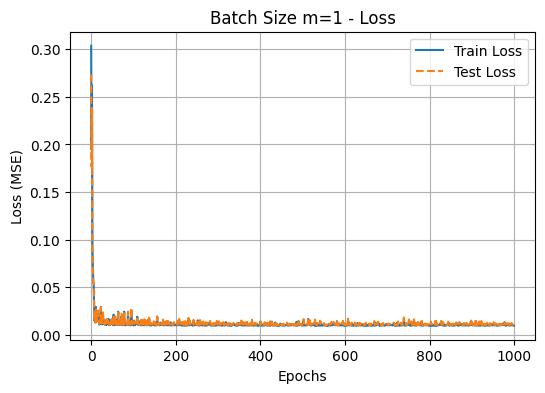

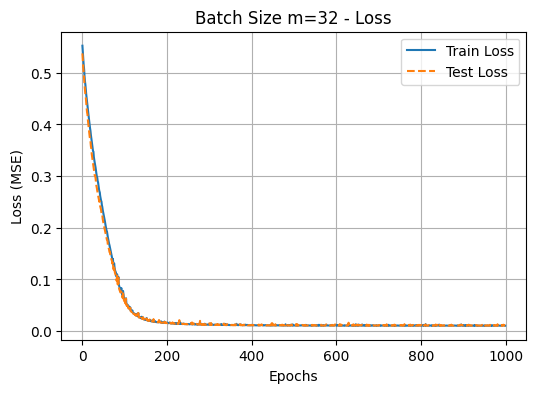

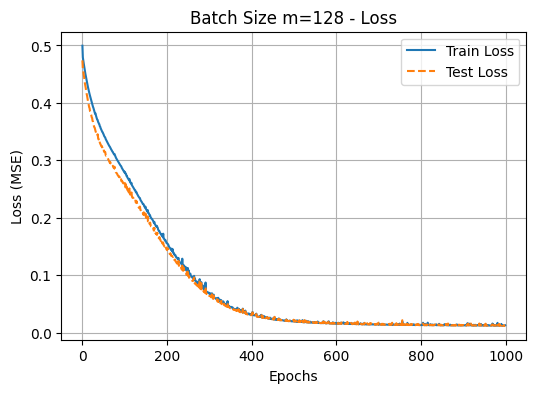

In [ ]:
for m in batch_sizes:
    model = sgd_results[m]["model"]

    plt.figure(figsize=(6,4))
    plt.plot(model.train_loss_history, label="Train Loss")
    plt.plot(model.test_loss_history, '--', label="Test Loss")
    plt.title(f"Batch Size m={m} - Loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss (MSE)")
    plt.legend()
    plt.grid(True)
    plt.show()

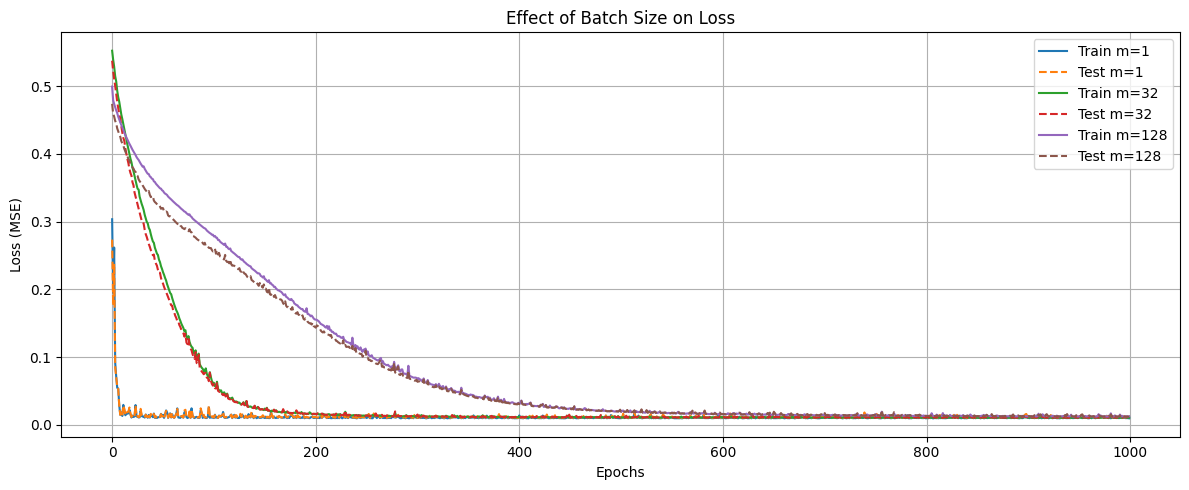

In [ ]:
plt.figure(figsize=(12,5))

plt.subplot(1, 1, 1)
for m in batch_sizes:
    model = sgd_results[m]["model"]
    plt.plot(model.train_loss_history, label=f"Train m={m}")
    plt.plot(model.test_loss_history, '--', label=f"Test m={m}")

plt.title("Effect of Batch Size on Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss (MSE)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

#### Observation: Effect of Batch Size (m)

- Batch size = 1 (pure SGD) will produce noisier loss curves but more frequent updates.
- Medium batch size (e.g., 32) often balances noise and stable convergence.
- Large batch sizes (e.g., 128) yield smoother but possibly slower convergence.
- Comparing loss curves helps visualize these trade-offs on the cosine dataset.
- In general as increasing batch size the loss cures noise decrease and converges slowly (may be due to near optimal parameters we may not observe these things)